## Minimal model for change detection

In [6]:
# Setup

from pathlib import Path

PROJECT_DIR = Path.cwd()
PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

STUDY_AREA = "Nepal, Syabru Besi"
TARGET_CRS = "EPSG:4326"

print(f"Project directory: {PROJECT_DIR}")
print(f"Study area: {STUDY_AREA}")
print(f"Target CRS: {TARGET_CRS}")

Project directory: c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project
Study area: Nepal, Syabru Besi
Target CRS: EPSG:4326


In [2]:
import geoai

from geoai.change_detection import (
    ChangeStarDetection,
    changestar_detect,
    list_changestar_models,
)

models = list_changestar_models()
for short_name, full_name in models.items():
    print(f"{short_name:30s} -> {full_name}")

INFO:numexpr.utils:NumExpr defaulting to 8 threads.
c:\Users\herol\miniconda3_v2\envs\sds320_v8\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\Users\herol\miniconda3_v2\envs\sds320_v8\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\Users\herol\miniconda3_v2\envs\sds320_v8\Lib\site-packages\torchange\models\changestar_1xd.py:81: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  @torch.amp.autocast('cuda', dtype=torch.float32)
c:\Users\herol\miniconda3_v2\envs\sds320_v8\Lib\site-packages\torchange\models\changestar_1xd.py:235: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  @torch.amp.autocast('cuda', dtype=torch.float32)


s0_s1c1_vitb                   -> s0_init_s1c1_changestar_vitb_1x256
s0_s1c5_vitb                   -> s0_init_s1c5_changestar_vitb_1x256
s0_s9c1_vitb                   -> s0_init_s9c1_changestar_vitb_1x256
s0_xview2_s1c5_vitb            -> s0_init_xView2_ft_s1c5_changestar_vitb_1x256
s1_s1c1_vitb                   -> s1_init_s1c1_changestar_vitb_1x256
s1_s1c1_vitl                   -> s1_init_s1c1_changestar_vitl_1x256
s9_s9c1_vitb                   -> s9_init_s9c1_changestar_vitb_1x256


In [14]:
path_before = DATA_DIR / 'raw' / 'sentinel2' / 's2_before_syabru_subset.tif'
path_after = DATA_DIR / 'raw' / 'sentinel2' / 's2_after_syabru_subset.tif'

In [26]:
path_before.as_posix()

'c:/Users/herol/OneDrive - Universität Zürich UZH/sds320/project/data/raw/sentinel2/s2_before_syabru_subset.tif'

In [ ]:
import leafmap



m = leafmap.Map()

# simplest: add a local GeoTIFF
m.add_raster(path_before.as_posix(), layer_name="before")
m


InvalidURL: Failed to parse: http://::1:51312/api/metadata?&filename=c%3A%5CUsers%5Cherol%5COneDrive+-+Universit%C3%A4t+Z%C3%BCrich+UZH%5Csds320%5Cproject%5Cdata%5Craw%5Csentinel2%5Cs2_before_syabru_subset.tif

In [12]:
leafmap.split_map(
path_before, path_after
)

The provided layers are invalid!


ValueError: left_layer must be one of the following: OpenStreetMap, Esri.WorldStreetMap, Esri.WorldImagery, Esri.WorldTopoMap, FWS NWI Wetlands, FWS NWI Wetlands Raster, NLCD 2021 CONUS Land Cover, NLCD 2019 CONUS Land Cover, NLCD 2016 CONUS Land Cover, NLCD 2013 CONUS Land Cover, NLCD 2011 CONUS Land Cover, NLCD 2008 CONUS Land Cover, NLCD 2006 CONUS Land Cover, NLCD 2004 CONUS Land Cover, NLCD 2001 CONUS Land Cover, USGS NAIP Imagery, USGS NAIP Imagery False Color, USGS NAIP Imagery NDVI, USGS Hydrography, USGS 3DEP Elevation, USGS 3DEP Elevation Index, ESA Worldcover 2020, ESA Worldcover 2020 S2 FCC, ESA Worldcover 2020 S2 TCC, ESA Worldcover 2021, ESA Worldcover 2021 S2 FCC, ESA Worldcover 2021 S2 TCC, USGS.Imagery, BaseMapDE.Color, BaseMapDE.Grey, BasemapAT.basemap, BasemapAT.grau, BasemapAT.highdpi, BasemapAT.orthofoto, BasemapAT.overlay, BasemapAT.surface, BasemapAT.terrain, CyclOSM, Esri.AntarcticBasemap, Esri.AntarcticImagery, Esri.ArcticImagery, Esri.ArcticOceanBase, Esri.Arc

In [8]:
import leafmap
import rioxarray as rxr

before = rxr.open_rasterio(path_before)
after = rxr.open_rasterio(path_after)

m = leafmap.Map(center=[0, 0], zoom=10)
m.split_map(
    before,
    after,
    left_args={"layer_name": "before", "colormap": "gray"},
    right_args={"layer_name": "after", "colormap": "gray"},
)
m


The provided layers are invalid!


ValueError: Failed to parse: http://::1:51312/api/metadata?&filename=%2Fvsimem%2Fc94cbd1f-1527-4e60-887d-fb6300f65c21%2Fc94cbd1f-1527-4e60-887d-fb6300f65c21.tif


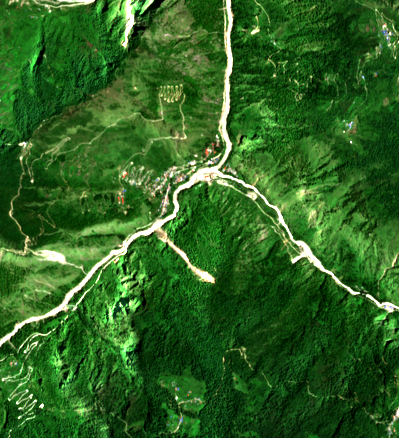
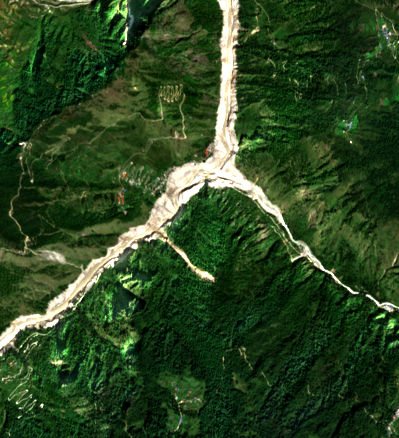

In [23]:
import folium
from folium.raster_layers import ImageOverlay
from rasterio.plot import reshape_as_image
import rasterio
import numpy as np
from branca.colormap import linear


def raster_to_bounds_and_image(path):
    with rasterio.open(path) as src:
        arr = src.read()
        bounds = src.bounds
        arr = reshape_as_image(arr)

        # handle nodata / scale for display
        img = arr[:, :, :3]
        img = img.astype(np.float32)

        # normalize to 0–255
        img_min = np.nanpercentile(img, 2)
        img_max = np.nanpercentile(img, 98)
        img = np.clip((img - img_min) / (img_max - img_min), 0, 1)
        img = (img * 255).astype(np.uint8)

        return img, [[bounds.bottom, bounds.left], [bounds.top, bounds.right]]

before_img, before_bounds = raster_to_bounds_and_image(path_before)
after_img, after_bounds = raster_to_bounds_and_image(path_after)

# center map on the average of both rasters
center_lat = (before_bounds[0][0] + before_bounds[1][0]) / 2
center_lon = (before_bounds[0][1] + before_bounds[1][1]) / 2

m = folium.Map(location=[center_lat, center_lon], zoom_start=12, tiles="OpenStreetMap")

ImageOverlay(
    image=before_img,
    bounds=before_bounds,
    opacity=0.7,
    name="Before"
).add_to(m)

ImageOverlay(
    image=after_img,
    bounds=after_bounds,
    opacity=0.7,
    name="After"
).add_to(m)

folium.LayerControl().add_to(m)

m


In [22]:
geoai.create_split_map(
    left_layer= str(path_before),
    right_layer= str(path_after),
    left_label="before",
    right_label="after"
)

The provided layers are invalid!


ValueError: Failed to parse: http://::1:54103/api/metadata?&filename=c%3A%5CUsers%5Cherol%5COneDrive+-+Universit%C3%A4t+Z%C3%BCrich+UZH%5Csds320%5Cproject%5Cdata%5Craw%5Csentinel2%5Cs2_before_syabru_subset.tif

## ChangeStar S1 VITB

In [5]:
from osgeo import gdal

detector = ChangeStarDetection(model_name="s1_s1c1_vitb")

INFO:httpx2:HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: HEAD https://huggingface.co/EVER-Z/Changen2-ChangeStar1x256/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx2:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/EVER-Z/Changen2-ChangeStar1x256/a51540d0abaca8f2b96ccd97139ccd4cfe55bd67/config.json?%2FEVER-Z%2FChangen2-ChangeStar1x256%2Fresolve%2Fmain%2Fconfig.json=&etag=%227602b10a701ea8ed91992247f5249ded5c2775fe%22 "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: HEAD https://huggingface.co/EVER-Z/Changen2-ChangeStar1x256/resolve/main/s1c1_cstar_vitb_1x256.pth "HTTP/1.1 302 Found"
2026-10-19 08:40:54, INFO:EVER:Load Changen2 pre-trained weight from EVER-Z/Changen2-ChangeStar1x256/s1c1_cstar_vitb_1x256.pth
2026-10-19 08:40:54, INFO:EVER:architecture: changestar_1x256 | backbone: vitb | modeling type: s1c1 | pre-trained data: Changen2-S1-15k | finetuned on: None


In [ ]:
result = detector.predict(
    path_before,
    path_after,
    output_change=str(RESULTS_DIR / "change_map.tif"),
    output_t1_semantic=str(RESULTS_DIR / "t1_buildings.tif"),
    output_t2_semantic=str(RESULTS_DIR / "t2_buildings.tif"),
    output_vector=str(RESULTS_DIR / "changes.gpkg"),
    tile_size=256, #fix tile size to avoid issues due to non-square input tiff files
    overlap=64
)

INFO:geoai.change_detection:No change polygons found.


In [12]:
print("Result keys:", list(result.keys()))
for key, value in result.items():
    if hasattr(value, "shape"):
        print(f"  {key}: shape={value.shape}, dtype={value.dtype}")
    else:
        print(f"  {key}: {value}")

Result keys: ['change_map', 'change_prob', 't1_semantic', 't2_semantic', 't1_semantic_prob', 't2_semantic_prob', 'num_semantic_classes']
  change_map: shape=(438, 399), dtype=uint8
  change_prob: shape=(438, 399), dtype=float32
  t1_semantic: shape=(438, 399), dtype=uint8
  t2_semantic: shape=(438, 399), dtype=uint8
  t1_semantic_prob: shape=(438, 399), dtype=float32
  t2_semantic_prob: shape=(438, 399), dtype=float32
  num_semantic_classes: 1


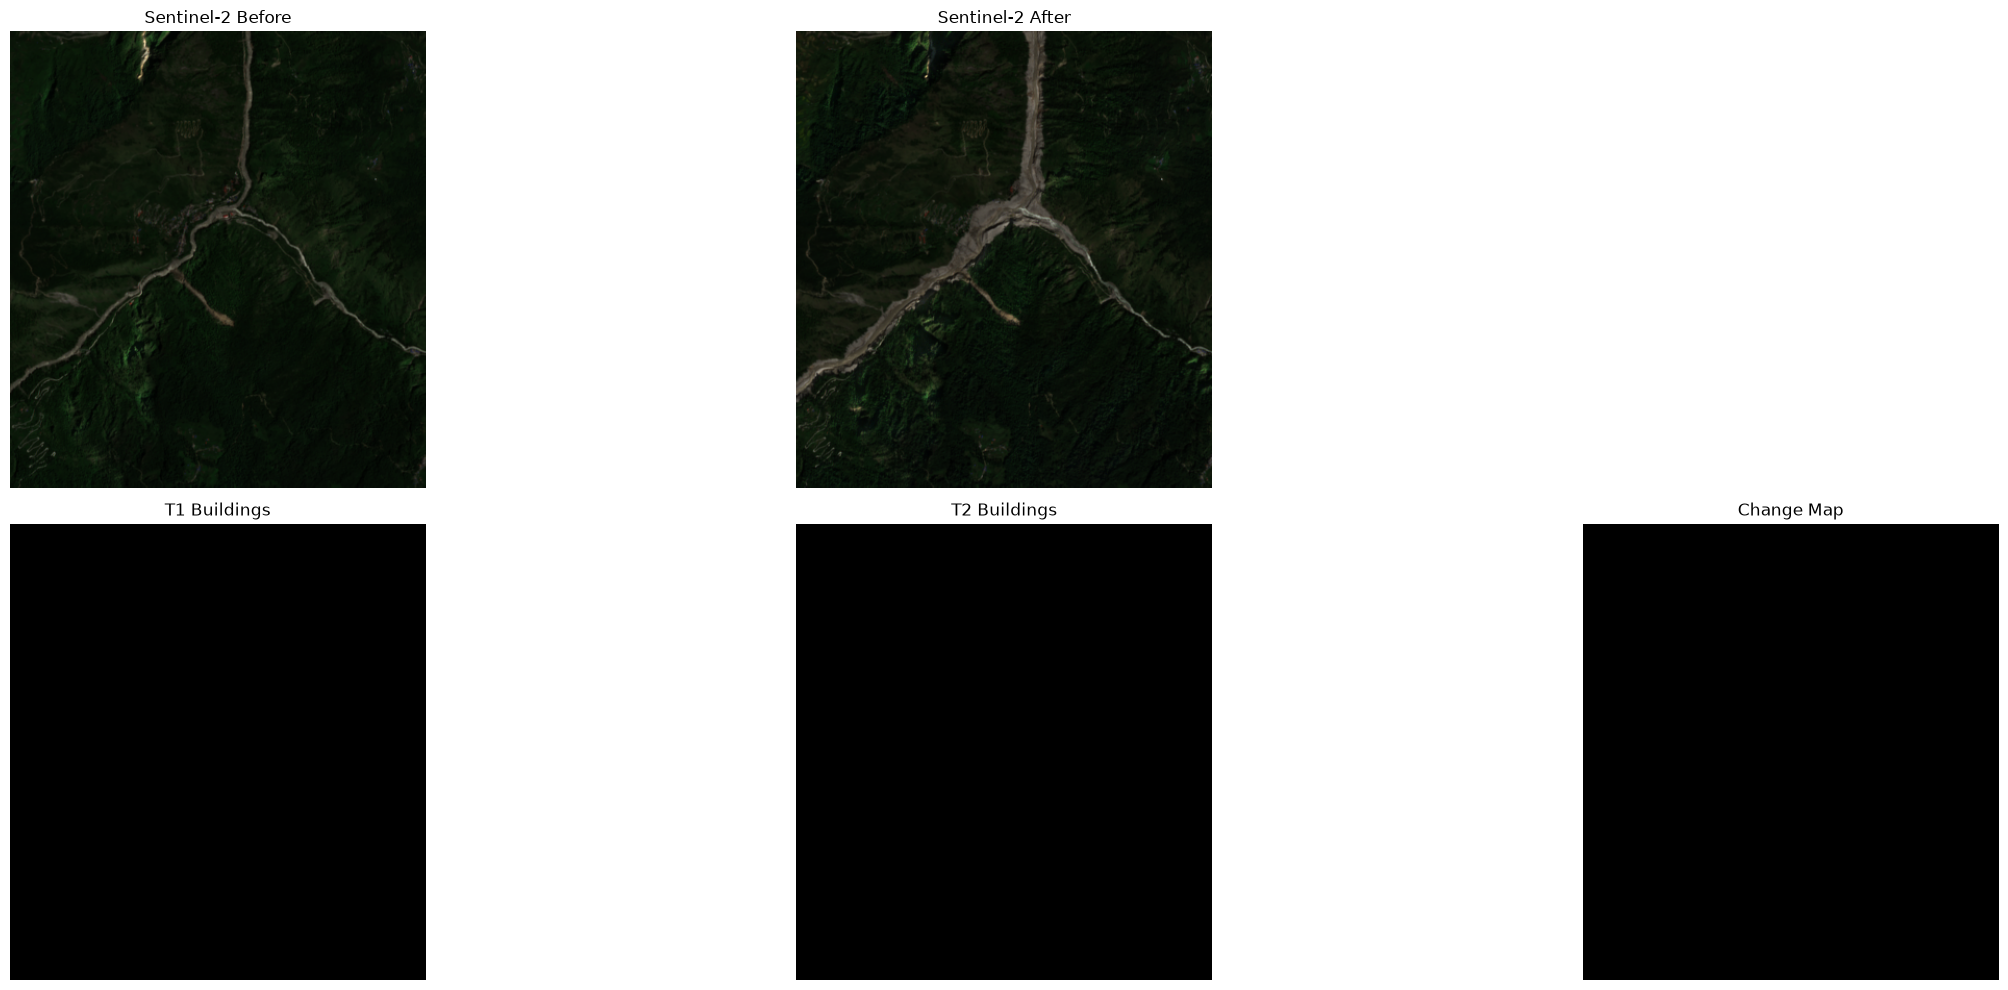

In [ ]:
import matplotlib.pyplot as plt

fig = detector.visualize(
    path_before,
    path_after,
    result=result,
    figsize=(25, 10),
    title1="Sentinel-2 Before",
    title2="Sentinel-2 After",
)
plt.show()

## ChangeStar S9 VITB

In [24]:
detector_s9 = ChangeStarDetection(model_name="s9_s9c1_vitb")
result_s9 = detector_s9.predict(    
    path_before,
    path_after,
    output_change=str(RESULTS_DIR / "change_map_s9.tif"),
    output_t1_semantic=str(RESULTS_DIR / "t1_buildings_s9.tif"),
    output_t2_semantic=str(RESULTS_DIR / "t2_buildings_s9.tif"),
    output_vector=str(RESULTS_DIR / "changes_s9.gpkg"),
    tile_size=256, #fix tile size to avoid issues due to non-square input tiff files
    overlap=64
)

INFO:httpx2:HTTP Request: HEAD https://huggingface.co/EVER-Z/Changen2-ChangeStar1x256/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx2:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/EVER-Z/Changen2-ChangeStar1x256/a51540d0abaca8f2b96ccd97139ccd4cfe55bd67/config.json?%2FEVER-Z%2FChangen2-ChangeStar1x256%2Fresolve%2Fmain%2Fconfig.json=&etag=%227602b10a701ea8ed91992247f5249ded5c2775fe%22 "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: HEAD https://huggingface.co/EVER-Z/Changen2-ChangeStar1x256/resolve/main/s9c1_cstar_vitb_1x256.pth "HTTP/1.1 302 Found"
INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/EVER-Z/Changen2-ChangeStar1x256/xet-read-token/a51540d0abaca8f2b96ccd97139ccd4cfe55bd67 "HTTP/1.1 200 OK"


s9c1_cstar_vitb_1x256.pth: reconstructing file:   0%|          |  0.00B /  400MB            

s9c1_cstar_vitb_1x256.pth: downloading bytes:           |  0.00B            

2026-10-17 15:23:23, INFO:EVER:Load Changen2 pre-trained weight from EVER-Z/Changen2-ChangeStar1x256/s9c1_cstar_vitb_1x256.pth
2026-10-17 15:23:23, INFO:EVER:architecture: changestar_1x256 | backbone: vitb | modeling type: s9c1 | pre-trained data: Changen2-S9-27k | finetuned on: None
INFO:pyogrio._io:Created 13 records


In [25]:
print("Result keys:", list(result.keys()))
for key, value in result_s9.items():
    if hasattr(value, "shape"):
        print(f"  {key}: shape={value.shape}, dtype={value.dtype}")
    else:
        print(f"  {key}: {value}")


Result keys: ['change_map', 'change_prob', 't1_semantic', 't2_semantic', 't1_semantic_prob', 't2_semantic_prob', 'num_semantic_classes']
  change_map: shape=(438, 399), dtype=uint8
  change_prob: shape=(438, 399), dtype=float32
  t1_semantic: shape=(438, 399), dtype=uint8
  t2_semantic: shape=(438, 399), dtype=uint8
  t1_semantic_prob: shape=(9, 438, 399), dtype=float32
  t2_semantic_prob: shape=(9, 438, 399), dtype=float32
  num_semantic_classes: 9


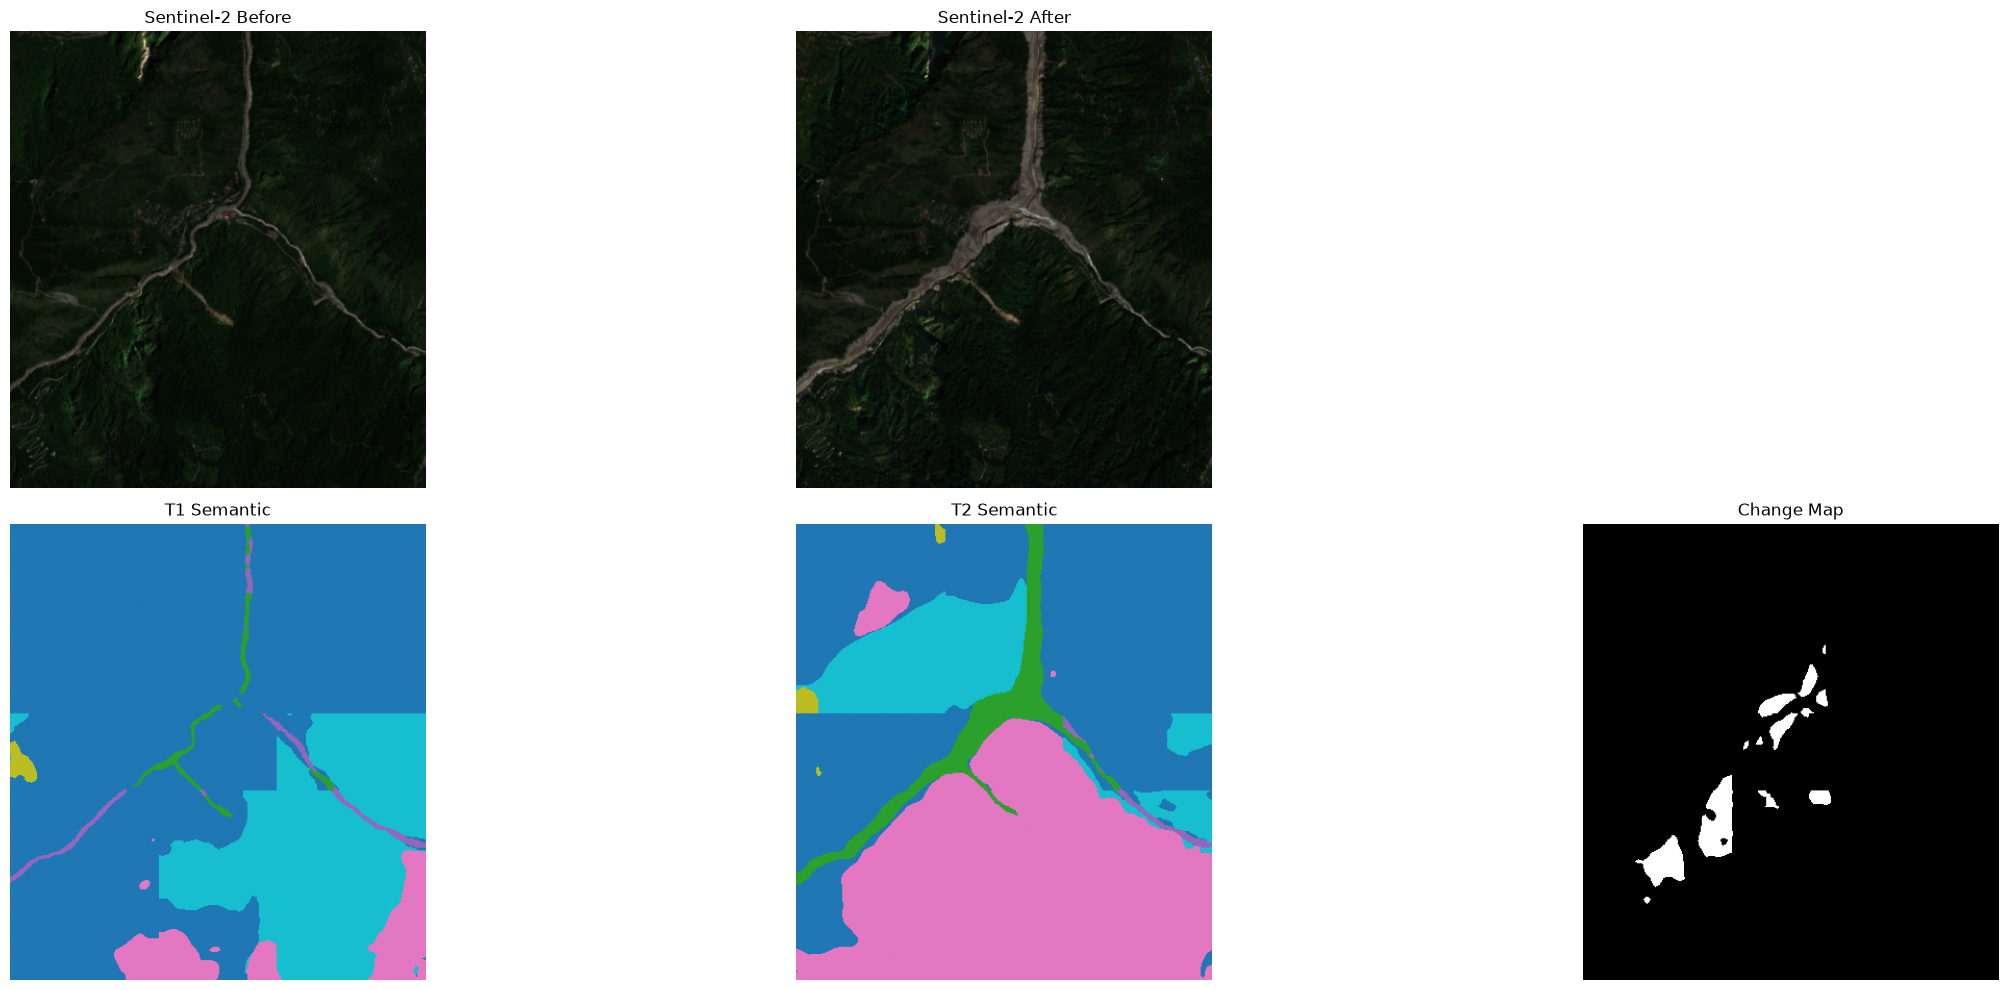

In [26]:
fig = detector.visualize(
    path_before,
    path_after,
    result=result_s9,
    figsize=(25, 10),
    title1="Sentinel-2 Before",
    title2="Sentinel-2 After",
)
plt.show()

## ChangeStar S1 VITL

In [6]:
detector_s1l = ChangeStarDetection(model_name="s1_s1c1_vitl")
result_s1l = detector_s1l.predict(    
    path_before,
    path_after,
    output_change=str(RESULTS_DIR / "change_map_s1l.tif"),
    output_t1_semantic=str(RESULTS_DIR / "t1_buildings_s1l.tif"),
    output_t2_semantic=str(RESULTS_DIR / "t2_buildings_s1l.tif"),
    output_vector=str(RESULTS_DIR / "changes_s1l.gpkg"),
    tile_size=256, #fix tile size to avoid issues due to non-square input tiff files
    overlap=64
)

INFO:httpx2:HTTP Request: HEAD https://huggingface.co/EVER-Z/Changen2-ChangeStar1x256/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx2:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/EVER-Z/Changen2-ChangeStar1x256/a51540d0abaca8f2b96ccd97139ccd4cfe55bd67/config.json?%2FEVER-Z%2FChangen2-ChangeStar1x256%2Fresolve%2Fmain%2Fconfig.json=&etag=%227602b10a701ea8ed91992247f5249ded5c2775fe%22 "HTTP/1.1 200 OK"
INFO:httpx2:HTTP Request: HEAD https://huggingface.co/EVER-Z/Changen2-ChangeStar1x256/resolve/main/s1c1_cstar_vitl_1x256.pth "HTTP/1.1 302 Found"
INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/EVER-Z/Changen2-ChangeStar1x256/xet-read-token/a51540d0abaca8f2b96ccd97139ccd4cfe55bd67 "HTTP/1.1 200 OK"


s1c1_cstar_vitl_1x256.pth: reconstructing file:   0%|          |  0.00B / 1.27GB            

s1c1_cstar_vitl_1x256.pth: downloading bytes:           |  0.00B            

2026-10-19 08:43:37, INFO:EVER:Load Changen2 pre-trained weight from EVER-Z/Changen2-ChangeStar1x256/s1c1_cstar_vitl_1x256.pth
2026-10-19 08:43:37, INFO:EVER:architecture: changestar_1x256 | backbone: vitl | modeling type: s1c1 | pre-trained data: Changen2-S1-15k | finetuned on: None
INFO:geoai.change_detection:No change polygons found.


In [8]:
print("Result keys:", list(result_s1l.keys()))
for key, value in result_s1l.items():
    if hasattr(value, "shape"):
        print(f"  {key}: shape={value.shape}, dtype={value.dtype}")
    else:
        print(f"  {key}: {value}")

Result keys: ['change_map', 'change_prob', 't1_semantic', 't2_semantic', 't1_semantic_prob', 't2_semantic_prob', 'num_semantic_classes']
  change_map: shape=(438, 399), dtype=uint8
  change_prob: shape=(438, 399), dtype=float32
  t1_semantic: shape=(438, 399), dtype=uint8
  t2_semantic: shape=(438, 399), dtype=uint8
  t1_semantic_prob: shape=(438, 399), dtype=float32
  t2_semantic_prob: shape=(438, 399), dtype=float32
  num_semantic_classes: 1


In [ ]:
fig = detector_s1l.visualize(
    path_before,
    path_after,
    result=result_s1l,
    figsize=(25, 10),
    title1="Sentinel-2 Before",
    title2="Sentinel-2 After",
)
plt.show()

## ChangeDetection with SAM

In [10]:
from geoai.change_detection import ChangeDetection
# Make sure model directory exists
Path("~/.cache/torch/hub/checkpoints/").expanduser().mkdir(parents=True, exist_ok=True)

# Initialize change detection
detector = ChangeDetection(sam_model_type="vit_h")

# Configure parameters (following the torchange example)
detector.set_hyperparameters(
    change_confidence_threshold=145,
    use_normalized_feature=True,
    bitemporal_match=True,
)

detector.set_mask_generator_params(
    points_per_side=32,
    stability_score_thresh=0.95,
)

print("Change detection system initialized!")

INFO:geoai.change_detection:Model checkpoint for vit_h not found.


INFO:geoai.utils.download:Extracted to: C:\Users\herol/.cache/torch/hub/checkpoints\archive


Change detection system initialized!


In [12]:
# Run change detection
results_sam = detector.detect_changes(
    path_before,
    path_after,
    output_path=str(RESULTS_DIR / "binary_mask_sam.tif"),
    export_probability=True,
    probability_output_path=str(RESULTS_DIR / "probability_mask_sam.tif"),
    export_instance_masks=True,
    instance_masks_output_path=str(RESULTS_DIR / "instance_masks_sam.tif"),
    return_detailed_results=True,
    return_results=False,
)

print(f"Change detection completed!")
print(f"Total instances detected: {results_sam['summary']['total_masks']}")
print(f"Image size: {results_sam['summary']['original_shape']}")

INFO:geoai.change_detection:Saved instance segmentation mask with 10 instances to c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\results\instance_masks_sam.tif
INFO:geoai.change_detection:Saved instance scores mask with 10 instances to c:\Users\herol\OneDrive - Universität Zürich UZH\sds320\project\results\instance_masks_sam_scores.tif


Change detection completed!
Total instances detected: 10
Image size: (438, 399)


In [13]:
# Display statistics
if "statistics" in results_sam and results_sam["statistics"]:
    print("Quality Statistics:")
    for metric, stats in results_sam["statistics"].items():
        print(f"  {metric}: mean={stats['mean']:.3f}, std={stats['std']:.3f}")

# Show top instances
if "masks" in results_sam and len(results_sam["masks"]) > 0:
    print("\nTop 5 detected instances:")
    for i, mask in enumerate(results_sam["masks"][:5]):
        print(
            f"  {i+1}. Instance {mask['mask_id']}: "
            f"IoU={mask['iou_pred']:.3f}, "
            f"Stability={mask['stability_score']:.3f}, "
            f"Area={mask['area']} pixels"
        )

Quality Statistics:
  iou_predictions: mean=0.913, std=0.036
  stability_scores: mean=0.970, std=0.008
  change_confidence: mean=-0.612, std=0.117
  areas: mean=1138.600, std=1931.956

Top 5 detected instances:
  1. Instance 6: IoU=0.910, Stability=0.980, Area=302 pixels
  2. Instance 5: IoU=0.917, Stability=0.974, Area=582 pixels
  3. Instance 4: IoU=0.929, Stability=0.971, Area=381 pixels
  4. Instance 7: IoU=0.892, Stability=0.967, Area=918 pixels
  5. Instance 0: IoU=0.956, Stability=0.977, Area=522 pixels


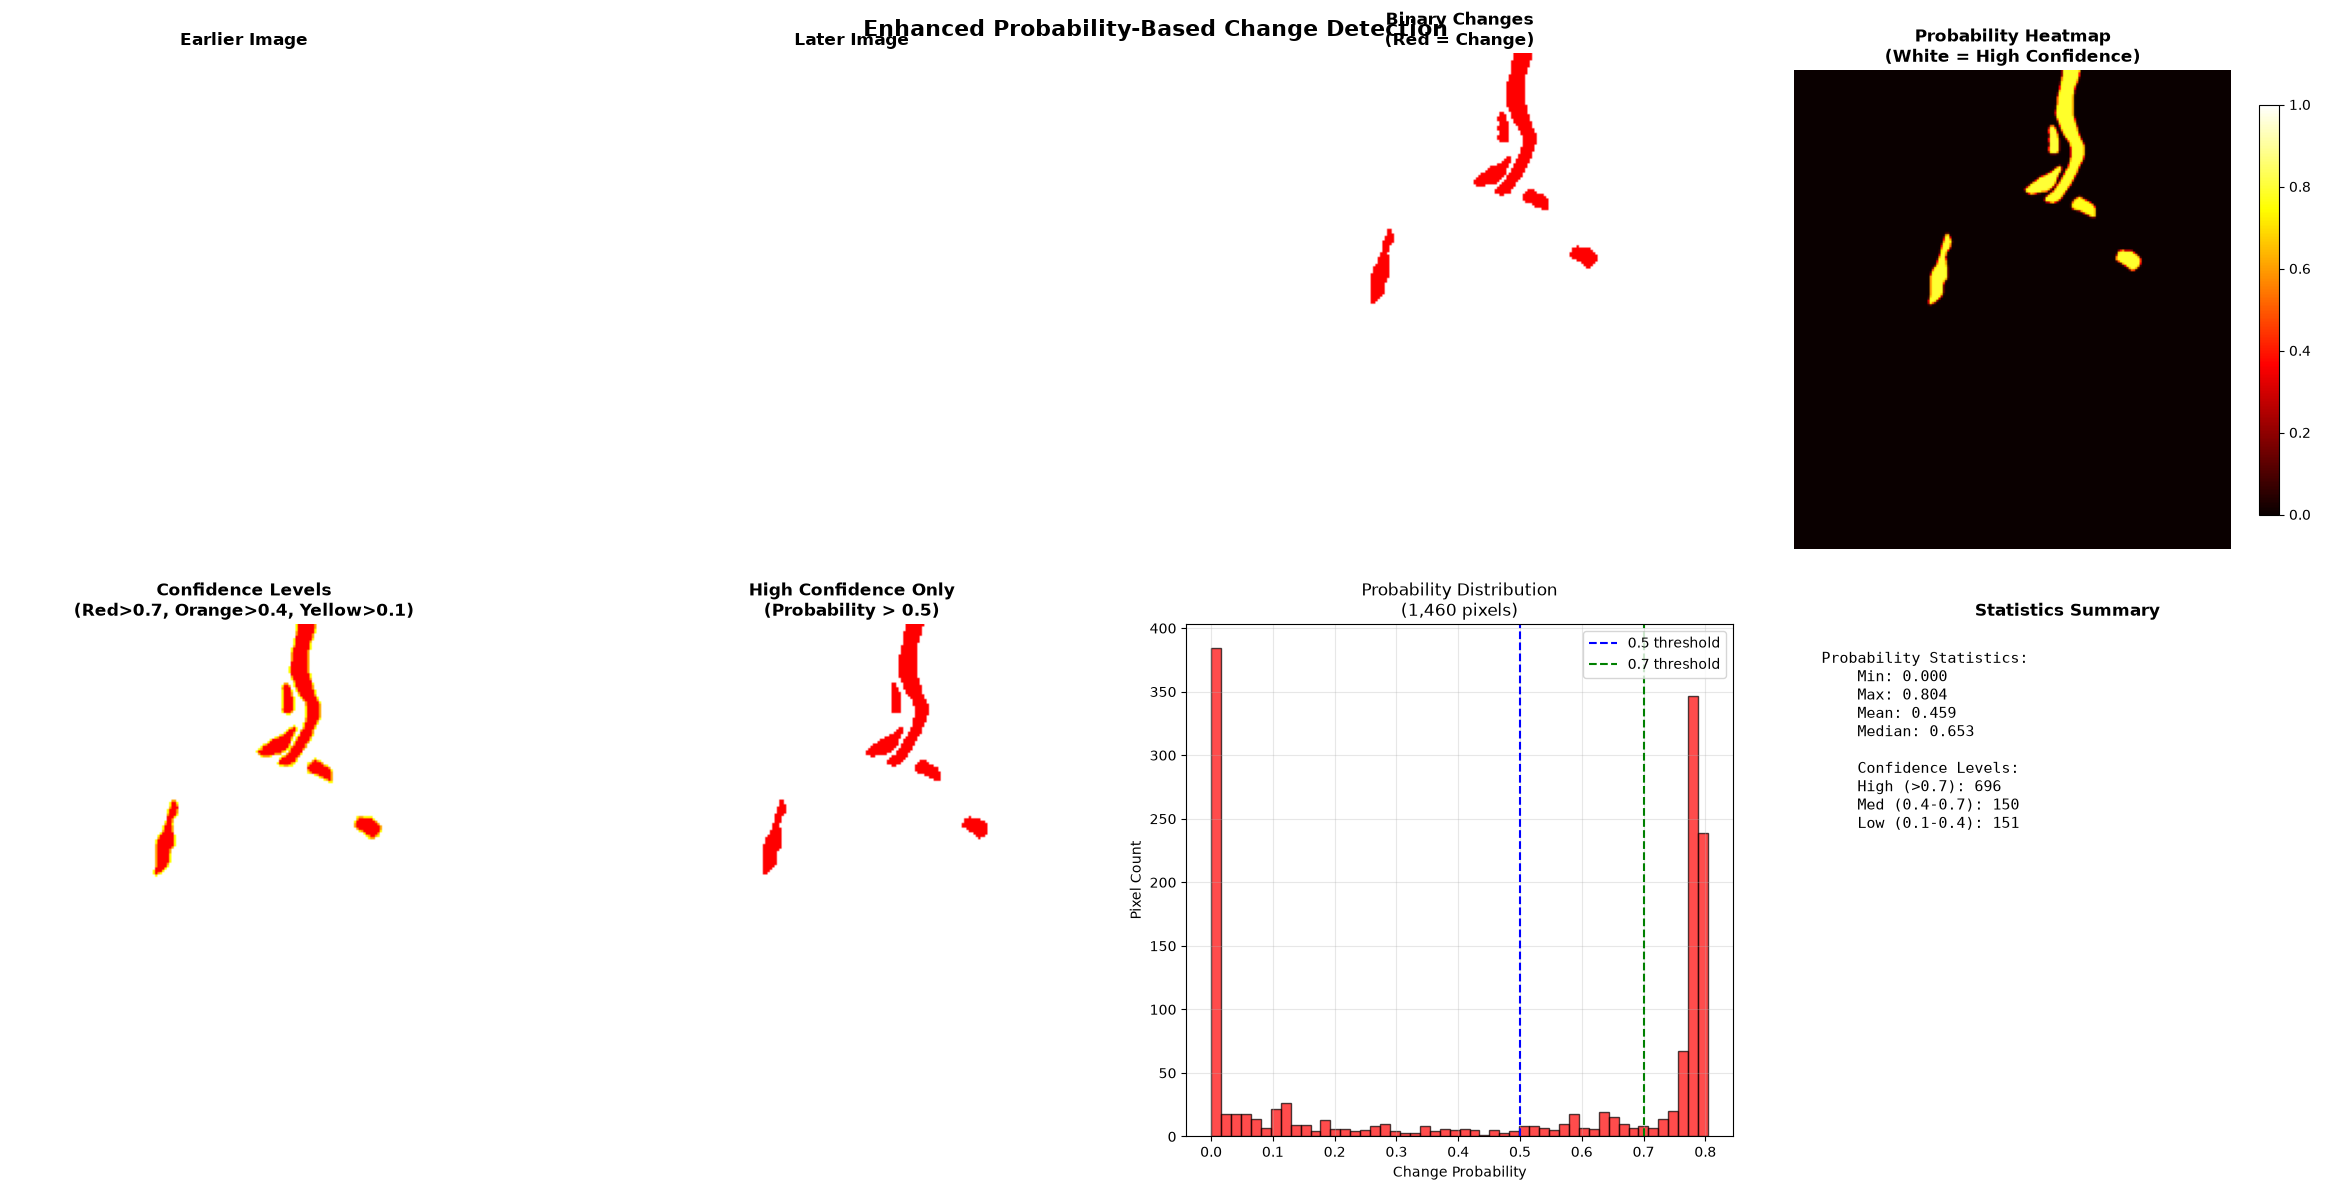

INFO:geoai.change_detection:Enhanced visualization saved as 'enhanced_probability_results.png'


In [15]:
# probability visualization
#rename output file to binary_mark_sam.tif
detector.visualize_results(
    path_before,
    path_after,
    str(RESULTS_DIR / "binary_mask_sam.tif"),
    str(RESULTS_DIR / "probability_mask_sam.tif")
)

## try CVA

In [18]:
import rasterio

with rasterio.open(path_before) as src:
    print(f"Number of bands: {src.count}")
    print(f"Width: {src.width}")
    print(f"Height: {src.height}")
    print(f"Band data types: {src.dtypes}")

Number of bands: 3
Width: 399
Height: 438
Band data types: ('uint16', 'uint16', 'uint16')


In [20]:
import numpy as np

with rasterio.open(path_before) as src:
    red_before = src.read(1).astype(np.float32)
    blue_before = src.read(2).astype(np.float32)
    green_before = src.read(3).astype(np.float32)

with rasterio.open(path_after) as src:
    red_after = src.read(1).astype(np.float32)
    blue_after = src.read(2).astype(np.float32)
    green_after = src.read(3).astype(np.float32)

delta_red = red_after - red_before
delta_blue = blue_after - blue_before
delta_green = green_after - green_before

magnitude = np.sqrt(delta_red**2 + delta_blue**2 + delta_green**2)
direction = np.degrees(np.arctan2(delta_green, delta_red)) #can't properly compute direction with 3 bands

mag_threshold = np.percentile(magnitude, 95)
significant_change = magnitude > mag_threshold

print(f"CVA magnitude range: {magnitude.min():.2f} to {magnitude.max():.2f}")
print(f"95th percentile threshold: {mag_threshold:.2f}")
print(f"Significant change pixels: {significant_change.sum():,}")

CVA magnitude range: 1.41 to 9634.17
95th percentile threshold: 866.25
Significant change pixels: 8,739


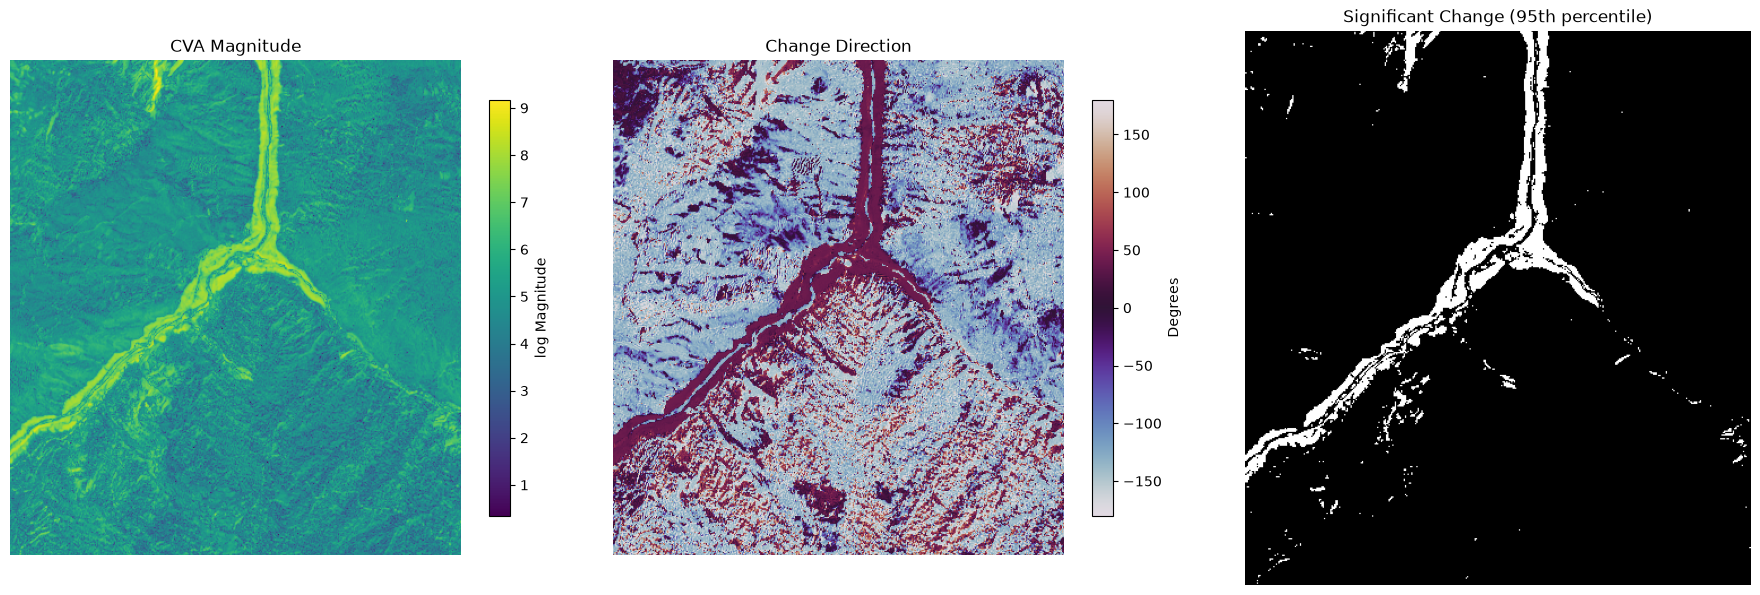

In [23]:
## plotting the results

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Change magnitude
im0 = axes[0].imshow(np.log(magnitude), cmap="viridis")
axes[0].set_title("CVA Magnitude")
plt.colorbar(im0, ax=axes[0], shrink=0.75, label="log Magnitude")

# 2. Change direction
im1 = axes[1].imshow(direction, cmap="twilight", vmin=-180, vmax=180)
axes[1].set_title("Change Direction")
plt.colorbar(im1, ax=axes[1], shrink=0.75, label="Degrees")

# 3. Significant change
axes[2].imshow(significant_change, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Significant Change (95th percentile)")

for ax in axes:
    ax.set_axis_off()

plt.tight_layout()
plt.show()

## SAR data

In [30]:
sar_before = DATA_DIR / 'raw' / 'sentinel1' / 's1_before_syabru_subset.tif'
sar_after = DATA_DIR / 'raw' / 'sentinel1' / 's1_after_syabru_subset.tif'

### changestar

In [ ]:
#changestar does not work for two channel inputs...

result__sar_s9 = detector_s9.predict(    
    sar_before,
    sar_after,
    output_change=str(RESULTS_DIR / "change_map_sar_s9.tif"),
    output_t1_semantic=str(RESULTS_DIR / "t1_buildings__sar_s9.tif"),
    output_t2_semantic=str(RESULTS_DIR / "t2_buildings_sar_s9.tif"),
    output_vector=str(RESULTS_DIR / "changes_sar_s9.gpkg"),
    tile_size=256, #fix tile size to avoid issues due to non-square input tiff files
    overlap=64
)

RuntimeError: Given groups=1, weight of size [768, 3, 16, 16], expected input[2, 2, 256, 256] to have 3 channels, but got 2 channels instead

### CVA

In [31]:
import numpy as np

with rasterio.open(sar_before) as src:
    vv_before = src.read(1).astype(np.float32)
    vh_before = src.read(2).astype(np.float32)

with rasterio.open(sar_after) as src:
    vv_after = src.read(1).astype(np.float32)
    vh_after = src.read(2).astype(np.float32)

delta_vv = vv_after - vv_before
delta_vh = vh_after - vh_before


magnitude = np.sqrt(delta_vv**2 + delta_vh**2)
direction = np.degrees(np.arctan2(delta_vh, delta_vv))

mag_threshold = np.percentile(magnitude, 95)
significant_change = magnitude > mag_threshold

print(f"CVA magnitude range: {magnitude.min():.2f} to {magnitude.max():.2f}")
print(f"95th percentile threshold: {mag_threshold:.2f}")
print(f"Significant change pixels: {significant_change.sum():,}")

CVA magnitude range: 0.00 to 9.46
95th percentile threshold: 0.32
Significant change pixels: 8,739


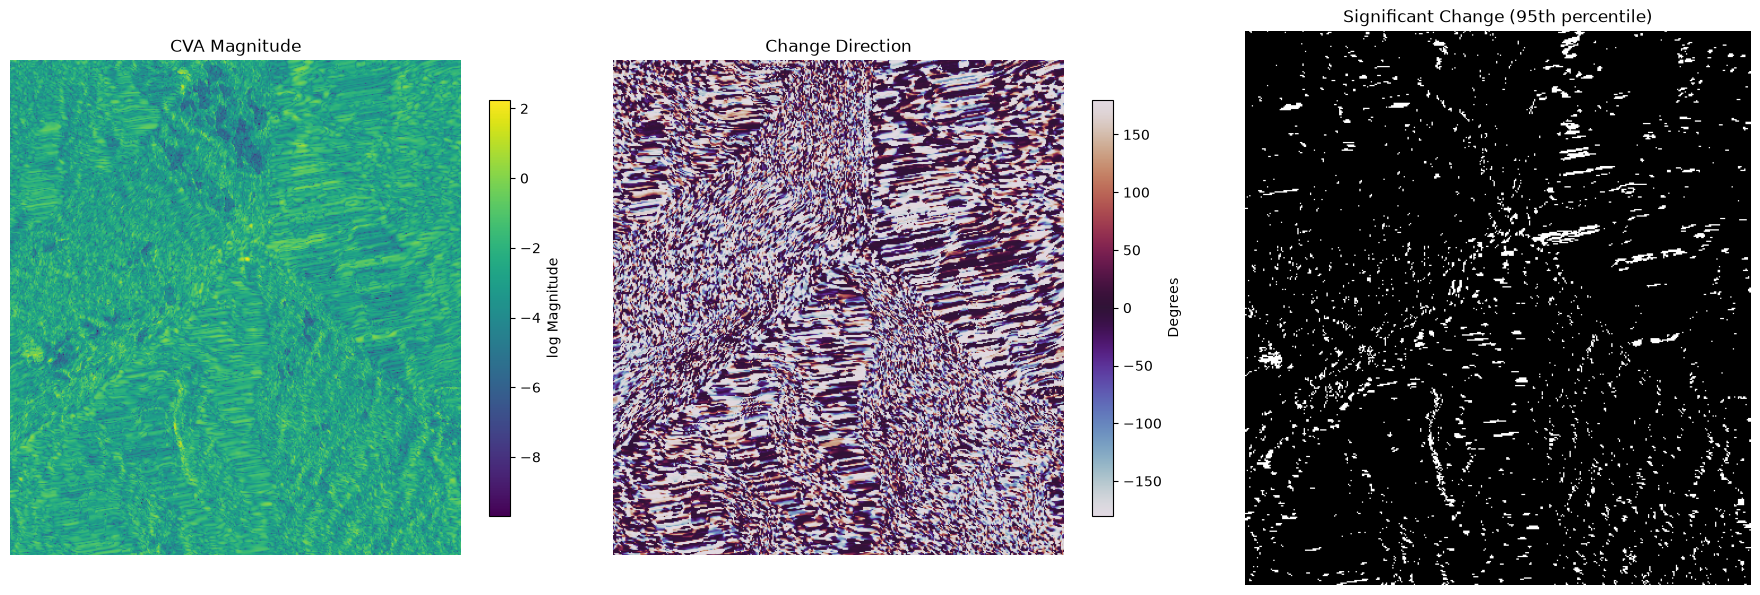

In [32]:
## plotting the results

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Change magnitude
im0 = axes[0].imshow(np.log(magnitude), cmap="viridis")
axes[0].set_title("CVA Magnitude")
plt.colorbar(im0, ax=axes[0], shrink=0.75, label="log Magnitude")

# 2. Change direction
im1 = axes[1].imshow(direction, cmap="twilight", vmin=-180, vmax=180)
axes[1].set_title("Change Direction")
plt.colorbar(im1, ax=axes[1], shrink=0.75, label="Degrees")

# 3. Significant change
axes[2].imshow(significant_change, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Significant Change (95th percentile)")

for ax in axes:
    ax.set_axis_off()

plt.tight_layout()
plt.show()